<a href="https://colab.research.google.com/github/jberisso/BA305-A1---hotel-bookings/blob/main/01_Prescriptive.Question.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


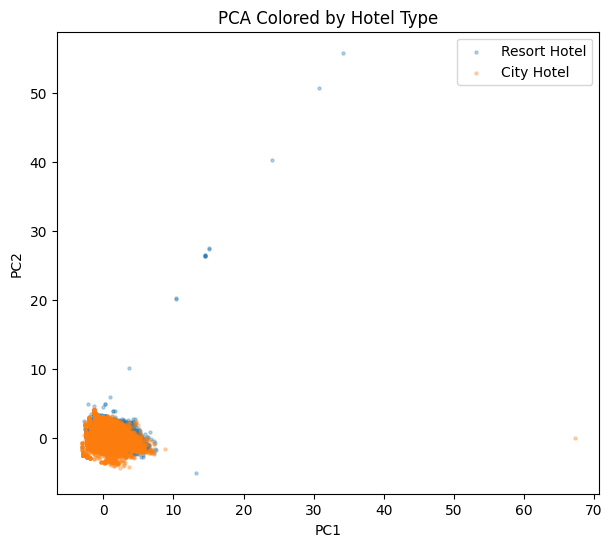

Explained variance ratio: [0.30273916 0.22357076]


In [3]:
features = ['lead_time', 'adr', 'adults', 'children', 'total_of_special_requests']
pca_data = df[features].fillna(0)

scaled = StandardScaler().fit_transform(pca_data)

pca = PCA(n_components=2)
pcs = pca.fit_transform(scaled)

plt.figure(figsize=(7, 6))
for h in df['hotel'].unique():
    mask = df['hotel'] == h
    plt.scatter(pcs[mask, 0], pcs[mask, 1], label=h, alpha=0.3, s=5)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend()
plt.title('PCA Colored by Hotel Type')
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)

In [4]:
pca_df = pd.DataFrame(pcs, columns=['PC1', 'PC2'], index=pca_data.index)
outliers = pca_df.sort_values('PC1', ascending=False).head(10)
df.loc[outliers.index, features + ['hotel', 'is_canceled']]

,lead_time,adr,adults,children,total_of_special_requests,hotel,is_canceled
48515,35,5400.0,2,0.0,0,City Hotel,1
2173,338,0.0,55,0.0,0,Resort Hotel,1
1643,336,0.0,50,0.0,0,Resort Hotel,1
1539,304,0.0,40,0.0,0,Resort Hotel,1
1917,349,0.0,27,0.0,0,Resort Hotel,1
1962,352,0.0,27,0.0,0,Resort Hotel,1
1587,333,0.0,26,0.0,0,Resort Hotel,1
1752,340,0.0,26,0.0,0,Resort Hotel,1
1884,347,0.0,26,0.0,0,Resort Hotel,1
2003,354,0.0,26,0.0,0,Resort Hotel,1


In [5]:
features = ['lead_time', 'adr', 'adults', 'children', 'total_of_special_requests']
df.groupby('hotel')[features].mean().round(2)

,lead_time,adr,adults,children,total_of_special_requests
hotel,,,,,
City Hotel,109.74,105.30,1.85,0.09,0.55
Resort Hotel,92.68,94.95,1.87,0.13,0.62


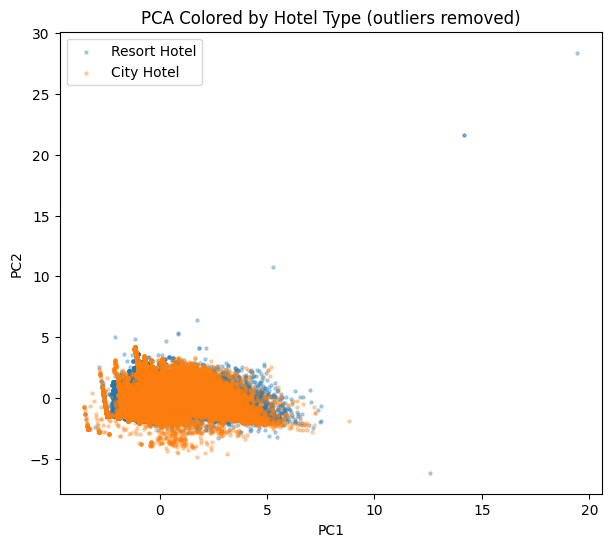

Explained variance ratio (outliers removed): [0.31415513 0.22390533]


In [6]:
clean_data = df.drop(index=outliers.index)
pca_data_clean = clean_data[features].fillna(0)
scaled_clean = StandardScaler().fit_transform(pca_data_clean)

pca_clean = PCA(n_components=2)
pcs_clean = pca_clean.fit_transform(scaled_clean)

plt.figure(figsize=(7, 6))
for h in clean_data['hotel'].unique():
    mask = clean_data['hotel'] == h
    plt.scatter(pcs_clean[mask, 0], pcs_clean[mask, 1], label=h, alpha=0.3, s=5)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend()
plt.title('PCA Colored by Hotel Type (outliers removed)')
plt.show()

print("Explained variance ratio (outliers removed):", pca_clean.explained_variance_ratio_)

In [7]:
components_df = pd.DataFrame(
    pca_clean.components_,
    columns=features,
    index=['PC1', 'PC2']
)
print(components_df.round(3))

# Which single feature contributes most to each component?
for pc in components_df.index:
    top_feature = components_df.loc[pc].abs().idxmax()
    print(f'{pc} is most driven by: {top_feature} (loading = {components_df.loc[pc, top_feature]:.3f})')

     lead_time    adr  adults  children  total_of_special_requests
PC1     -0.072  0.644   0.443     0.475                      0.398
PC2      0.790 -0.017   0.544    -0.236                     -0.155
PC1 is most driven by: adr (loading = 0.644)
PC2 is most driven by: lead_time (loading = 0.790)
